In [14]:
import sys
from pathlib import Path

# Find project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Add project root to Python path
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO

from src.config import (
    MODEL_PATH,
    INPUT_DIR,
    OUTPUT_DIR,
    CONFIDENCE_THRESHOLD,
    IMAGE_SIZE
)

print("All libraries imported successfully!")
print("Project Root:", PROJECT_ROOT)
print("Model Exists:", MODEL_PATH.exists())

All libraries imported successfully!
Project Root: c:\Users\ASUS\OneDrive\Desktop\20-Day-AI-ML-Internship\Day-12
Model Exists: True


In [15]:
# Load pretrained YOLOv8 Nano model

model = YOLO(str(MODEL_PATH))

print("YOLO Model Loaded Successfully!")
print("Model Name: YOLOv8 Nano")
print("Model Path:", MODEL_PATH)
print("Confidence Threshold:", CONFIDENCE_THRESHOLD)
print("Image Size:", IMAGE_SIZE)

YOLO Model Loaded Successfully!
Model Name: YOLOv8 Nano
Model Path: C:\Users\ASUS\OneDrive\Desktop\20-Day-AI-ML-Internship\Day-12\models\yolov8n.pt
Confidence Threshold: 0.25
Image Size: 640


In [16]:
# Load detection results and batch summary

detection_file = OUTPUT_DIR / "detection_results.csv"
summary_file = OUTPUT_DIR / "batch_summary.csv"

detection_df = pd.read_csv(detection_file)
summary_df = pd.read_csv(summary_file)

print("Detection Results:")
display(detection_df)

print("\nBatch Summary:")
display(summary_df)

Detection Results:


,Image,Class_ID,Class_Name,Confidence,X1,Y1,X2,Y2
0,bus.jpg,5,bus,0.8734,22.87,231.28,805.00,756.84
1,bus.jpg,0,person,0.8657,48.55,398.55,245.35,902.70
2,bus.jpg,0,person,0.8528,669.47,392.19,809.72,877.04
3,bus.jpg,0,person,0.8252,221.52,405.80,344.97,857.54
4,bus.jpg,0,person,0.2611,0.00,550.53,63.01,873.44
5,bus.jpg,11,stop sign,0.2551,0.06,254.46,32.56,324.87
6,zidane.jpg,0,person,0.8360,114.87,197.41,1114.47,711.89
7,zidane.jpg,0,person,0.8190,748.46,41.86,1143.08,713.02
8,zidane.jpg,27,tie,0.2910,439.47,437.07,524.35,709.16



Batch Summary:


,Image,Total_Objects
0,bus.jpg,6
1,zidane.jpg,3


In [17]:
# Generate detection dataset summary

total_images = len(summary_df)
total_objects = len(detection_df)
unique_classes = detection_df["Class_Name"].nunique()

print("========== YOLO INFERENCE SUMMARY ==========")
print("Total Images Processed:", total_images)
print("Total Objects Detected:", total_objects)
print("Unique Object Classes:", unique_classes)

print("\nClass-wise Detection Count:")
print(detection_df["Class_Name"].value_counts())

print("\nAverage Confidence Score:",
      round(detection_df["Confidence"].mean(), 4))

========== YOLO INFERENCE SUMMARY ==========
Total Images Processed: 2
Total Objects Detected: 9
Unique Object Classes: 4

Class-wise Detection Count:
Class_Name
person       6
bus          1
stop sign    1
tie          1
Name: count, dtype: int64

Average Confidence Score: 0.6533


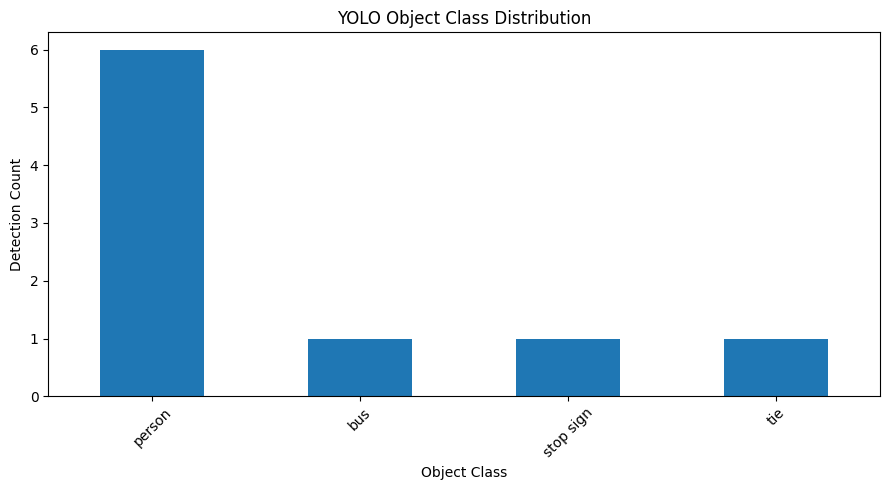

Class distribution graph saved successfully!


In [18]:
# Visualize object class distribution

class_counts = detection_df["Class_Name"].value_counts()

plt.figure(figsize=(9, 5))
class_counts.plot(kind="bar")

plt.title("YOLO Object Class Distribution")
plt.xlabel("Object Class")
plt.ylabel("Detection Count")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "plots" / "class_distribution_notebook.png")
plt.show()

print("Class distribution graph saved successfully!")

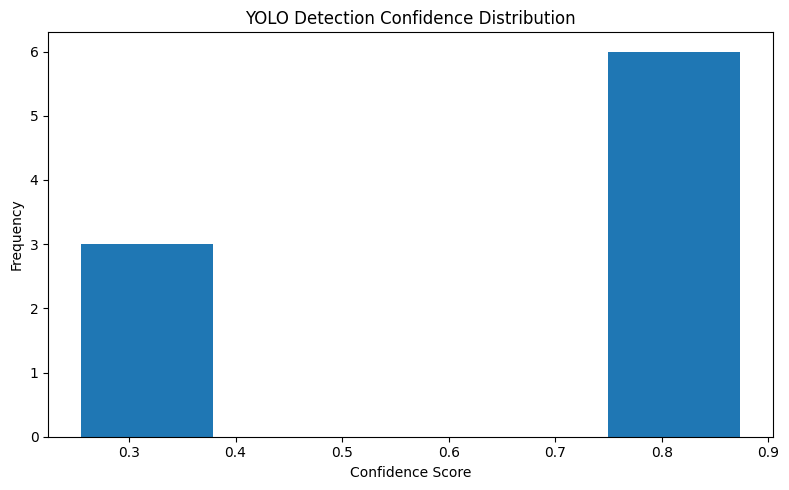

Confidence distribution graph saved successfully!


In [19]:
# Visualize detection confidence scores

plt.figure(figsize=(8, 5))

plt.hist(detection_df["Confidence"], bins=5)

plt.title("YOLO Detection Confidence Distribution")
plt.xlabel("Confidence Score")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "plots" / "confidence_distribution_notebook.png")
plt.show()

print("Confidence distribution graph saved successfully!")

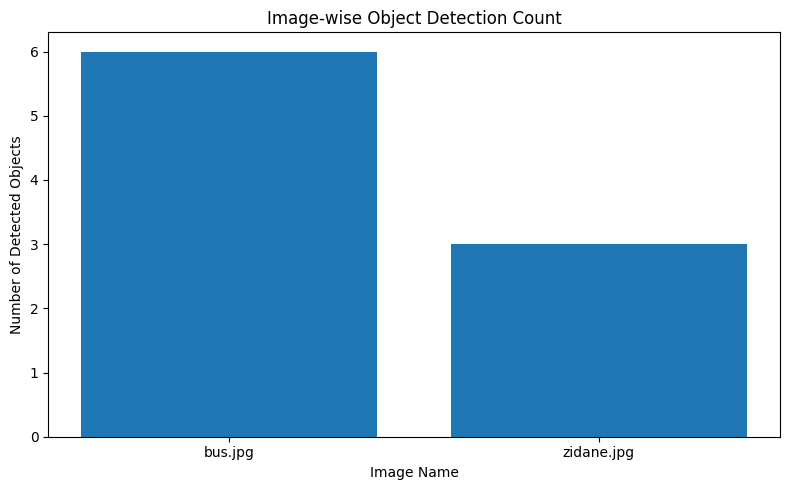

Image-wise object count graph saved successfully!


In [20]:
# Visualize image-wise object detection count

plt.figure(figsize=(8, 5))

plt.bar(
    summary_df["Image"],
    summary_df["Total_Objects"]
)

plt.title("Image-wise Object Detection Count")
plt.xlabel("Image Name")
plt.ylabel("Number of Detected Objects")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "plots" / "image_object_count_notebook.png")
plt.show()

print("Image-wise object count graph saved successfully!")

In [21]:
# Generate YOLO inference observations

observations = f"""
# YOLO Inference Analysis - Day 12

## Project Overview
Pretrained YOLOv8 Nano model was used for object detection.

## Dataset Summary
- Total Images Processed: {total_images}
- Total Objects Detected: {total_objects}
- Unique Object Classes: {unique_classes}

## Class-wise Detection
{detection_df["Class_Name"].value_counts().to_string()}

## Confidence Analysis
- Average Confidence: {detection_df["Confidence"].mean():.4f}
- Confidence Threshold: {CONFIDENCE_THRESHOLD}

## Image-wise Detection
{summary_df.to_string(index=False)}

## Key Observations
1. YOLO successfully detected objects in both sample images.
2. Person was the most frequently detected class.
3. Different objects received different confidence scores.
4. Annotated images and detection results were saved successfully.

## Conclusion
YOLOv8 Nano performed object detection on sample images
and generated bounding boxes, class labels, and confidence scores.
"""

report_path = PROJECT_ROOT / "reports" / "inference_observations.md"
report_path.write_text(observations, encoding="utf-8")

print("Inference observation report saved successfully!")
print("Location:", report_path)

Inference observation report saved successfully!
Location: c:\Users\ASUS\OneDrive\Desktop\20-Day-AI-ML-Internship\Day-12\reports\inference_observations.md


In [22]:
# Verify all Day-12 output files

required_files = [
    OUTPUT_DIR / "detection_results.csv",
    OUTPUT_DIR / "batch_summary.csv",
    OUTPUT_DIR / "annotated_images" / "bus_detected.jpg",
    OUTPUT_DIR / "annotated_images" / "zidane_detected.jpg",
    OUTPUT_DIR / "plots" / "class_distribution.png",
    OUTPUT_DIR / "plots" / "image_object_count.png",
    OUTPUT_DIR / "plots" / "confidence_distribution.png",
    PROJECT_ROOT / "reports" / "inference_observations.md"
]

print("========== FINAL OUTPUT VERIFICATION ==========")

for file in required_files:
    status = "FOUND" if file.exists() else "MISSING"
    print(f"{file.name}: {status}")

========== FINAL OUTPUT VERIFICATION ==========
detection_results.csv: FOUND
batch_summary.csv: FOUND
bus_detected.jpg: FOUND
zidane_detected.jpg: FOUND
class_distribution.png: FOUND
image_object_count.png: FOUND
confidence_distribution.png: FOUND
inference_observations.md: FOUND
